In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import requests as rq
import numpy as np
import time
import os
import contextily as ctx

L'implantation des nouvelles méga-usines (batteries, hydrogène, data centers) se fait-elle de manière aveugle dans des bassins versants déjà condamnés à un épuisement de leurs nappes phréatiques ?

# Problématique : Dans quelle mesure l'exposition locale aux activités industrielles (ICPE) amplifie-t-elle la vulnérabilité et la baisse de niveau des nappes phréatiques face aux sécheresses récurrentes (2015-2026) dans le département du Nord ?

## Récupération des données

### Récupération des données sur les installations industrielles
On utilise l'API de Georisques pour récupérer les informations sur les usines.

In [2]:
#On crée le dossier data qui va stocker toutes nos données :
os.makedirs("../../data", exist_ok=True)

#On récupère la liste des installations industrielles à l'échelle nationale sur le site de l'ICPE
url_icpe = "https://mapsref.brgm.fr/wxs/georisques/georisques_dl?&service=wfs&version=2.0.0&request=getfeature&typename=InstallationsClassees&outputformat=CSVTEXT"

fichier_icpe = rq.get(url_icpe)
lien_stockage_physique_icpe = "../../data/icpe.csv"

if fichier_icpe.status_code == 200:
    with open(lien_stockage_physique_icpe, "wb") as f:
        f.write(fichier_icpe.content)
    print("Fichier téléchargé.")
else:
    print("Erreur avec le téléchargement du fichier ICPE.")

Fichier téléchargé.


On a  136244 installations industrielles. Dont  104742 installations industrielles ICPE.
On ne garde que les  43739 installations industrielles pures.


Text(0, 0.5, "Nombre d'installations industrielles")

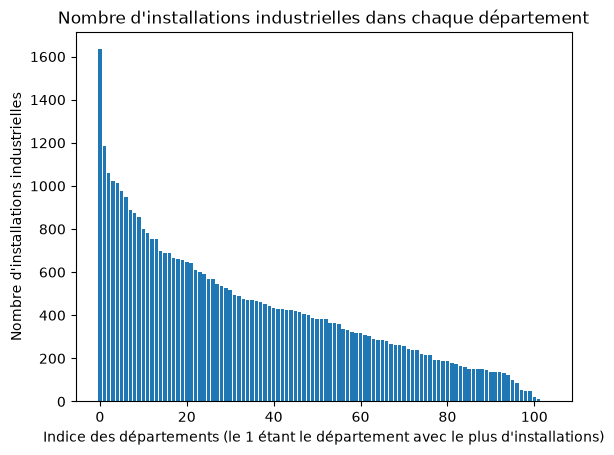

In [3]:
# On récupère donc la liste des installations industrielles
installations_indust = pd.read_csv(lien_stockage_physique_icpe, sep=";", encoding='utf-8')
print("On a ", installations_indust.shape[0], "installations industrielles.", end="")
installations_indust = installations_indust.loc[installations_indust["lib_regime"] != "Non ICPE"]
print(" Dont ", installations_indust.shape[0], "installations industrielles ICPE.")

#On veut garder uniquement les installations industrielles pures (pas l'agriculture et l'élevage par ex)
installations_indust = (installations_indust.loc[
    (installations_indust["industrie"] == 1)
    & (installations_indust["bovins"] == 0)
    & (installations_indust["porcs"] == 0)
    & (installations_indust["volailles"] == 0)
    & (installations_indust["eolienne"] == 0)
    ])
print("On ne garde que les ", installations_indust.shape[0], "installations industrielles pures.")

#On classe les départements qui ont le plus d'installations industrielles pour limiter la recherche (car les données sur Hub'eau sont trop volumineuses pour traiter la France entière)
classement_dpt = (installations_indust.groupby("num_dep")
    .size()
    .sort_values(ascending=False)
    )
plt.bar(range(classement_dpt.shape[0]), classement_dpt.values)
plt.title("Nombre d'installations industrielles dans chaque département")
plt.xlabel("Indice des départements (le 1 étant le département avec le plus d'installations)")
plt.ylabel("Nombre d'installations industrielles")

On va donc prendre le département qui contient le plus d'installations industrielles pour notre analyse.  
En effet, Hub'eau API nous donne un très grand volume de données et nous devons nous limiter dans notre recherche à quelques départements.  
Avec le graphique ci-dessus, on voit que le département 59 est de loin le plus grand centre industriel français.  
Nous nous concentrerons donc sur le département 59 pour la suite de l'analyse.  

In [4]:
departement_cible = classement_dpt.index[0]
print("Département analysé : ", departement_cible)

Département analysé :  59


Mise en forme des données géographiques avec Geopandas

In [5]:
installations_indust = installations_indust.loc[installations_indust["num_dep"] == departement_cible]

#On vérifie qu'il n'y a pas d'installations industrielles sans coordonnées géographiques dans la base de données ICPE des installations industrielles du 59
nb_position_less = installations_indust.loc[installations_indust["x"].isnull() | installations_indust["y"].isnull() | installations_indust["code_epsg"].isnull()].shape[0]
print(nb_position_less, "installations industrielles n'ont pas de coordonnées géographiques.")
installations_indust = installations_indust.loc[installations_indust["x"].notnull() & installations_indust["y"].notnull() & installations_indust["code_epsg"].notnull()]

#On utilise les coordonnées des installations pour les localiser avec Geopandas
installations_indust["geometry"] = None #Colonne qui va prendre la valeur position Geopandas
codes_epsg_type_coord = installations_indust["code_epsg"].unique()   #On veut que ça marche pour les différents types de référentiels (x,y)
for epsg in codes_epsg_type_coord:
    filtre = installations_indust["code_epsg"] == epsg
    points = gpd.points_from_xy(
        installations_indust.loc[filtre, "x"], 
        installations_indust.loc[filtre, "y"]
    )
    serie_geometrique = gpd.GeoSeries(points, crs=f"EPSG:{int(epsg)}")
    serie_geometrique = serie_geometrique.to_crs("EPSG:2154") #On ramène tout sous le même format
    installations_indust.loc[filtre, "geometry"] = serie_geometrique.values

#On définit un GeoDataFrame pour les études géométriques :
installations_indust = gpd.GeoDataFrame(installations_indust, geometry="geometry", crs="EPSG:2154")

0 installations industrielles n'ont pas de coordonnées géographiques.


### Récupération des données sur les nappes phréatiques du 59

L'API Hub'eau ne permet pas d'envoyer toutes les stations d'un coup.  
Encore moins toutes les chroniques d'un coup.  
Donc on sélectionne que la région pour laquelle on a vu qu'il y avait une grande concentration d'industrie : le 59

In [8]:
#On récupère les stations de mesure des nappes phréatiques sur le site Hubeau
url_stations = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/stations"
stations = []

params = {"code_departement": departement_cible, "size": 5000, "format": "json"}
fichier_stations = rq.get(url_stations, params=params)

if fichier_stations.status_code == 200:
    data = fichier_stations.json()
    stations.extend(data["data"])
    print("Fichier téléchargé.")
else:
    print(fichier_stations.status_code)
    print("Erreur avec le téléchargement du fichier stations Hubeau.")

stations = pd.DataFrame(stations)
stations.to_csv("../../data/stations_nappes.csv", encoding='utf-8')
print("On a récupéré ", stations.shape[0], "stations de mesure des nappes phréatiques dans le département ", departement_cible, ".")

Fichier téléchargé.
On a récupéré  730 stations de mesure des nappes phréatiques dans le département  59 .


Mise en forme des données géographiques avec Geopandas

In [50]:
#On vérifie qu'il n'y a pas d'installations industrielles sans coordonnées géographiques dans la base de données ICPE des installations industrielles du 59
nb_position_less = stations.loc[stations["x"].isnull() | stations["y"].isnull()].shape[0]
print(nb_position_less, "stations n'ont pas de coordonnées géographiques.")
stations = stations.loc[stations["x"].notnull() & stations["y"].notnull()]

#On crée le modèle Geopandas
stations = gpd.GeoDataFrame(
    stations,
    geometry=gpd.points_from_xy(stations['x'], stations['y']),
    crs="EPSG:4326"
).to_crs(epsg=2154) #On ramène tout sous le même format que les installations industrielles

0 stations n'ont pas de coordonnées géographiques.


Pour chaque station identifiée dans les départements contenant le plus d'industrie, on récupère les séries temporelles de niveau des nappes phréatiques entre janvier 2015 et janvier 2026

In [53]:
#On ne peut pas récupérer le volume des nappes phréatiques pour toutes les stations en même temps.


#On veut récupérer les volumes des nappes phréatiques pour chaque station
url_chroniques_api = "https://hubeau.eaufrance.fr/api/v1/niveaux_nappes/chroniques"
chroniques = []

#Quand on essaye de récupérer toutes les données de toutes les nappes, on a une erreur 414 : la requête URL est trop longue avec tous les code_bss en paramètres.
#Donc on va diviser les données de 700 stations à récupérer en paquets de 50.

liste_codes_bss_stations = stations["code_bss"].tolist()
paquets_intermediaires = []
for i in range(0, stations.shape[0], 50):
    paquets_intermediaires.append(liste_codes_bss_stations[i:i+50])
print("Nombre de stations par paquets : ", [len(x) for x in paquets_intermediaires])

for paquet in paquets_intermediaires:
    params_api = {"code_bss":",".join(paquet), "size":5000, "format":"json", "date_debut_mesure":"2015-01-01", "date_fin_mesure":"2026-01-01"}

    #Le problème est que le volume de données retourné est trop important. => On obtient une erreur 206 pour chaque paquet.
    #Il faut donc récupérer les premières informations renvoyées par l'API et aller chercher la page suivante.
    url = url_chroniques_api
    while url != None:
        try:
            fichier_chroniques = rq.get(url, params=params_api, timeout=20)    #On met un timeout pour rapidement recommencer la requête si ça marche pas.
        except Exception as e:
            print("Erreur requête : ", end="")
            print(e)
            print("Pas grave, on va réessayer.")
            continue
           #On recommence en haut de la boucle sur la même URL
        if fichier_chroniques.status_code == 200 or fichier_chroniques.status_code == 206:
            data = fichier_chroniques.json()
            chroniques.extend(data["data"])
            url = data.get("next")
            params_api = None   #Il semble que cette information soit déjà intégrée dans l'url de la page "next"
            print("Sous-paquet téléchargé.")
            time.sleep(1)   #On attend 1 sec pour éviter de se faire rejeter par le serveur
        else:
            print(fichier_chroniques.status_code)
            print("Erreur avec le téléchargement du fichier stations Hubeau.")
            time.sleep(1)   #On attend 1 seconde et on recommence au cas où ça se répare tout seul
print("Téléchargement des donné réussi !")

chroniques = pd.DataFrame(chroniques)
chroniques.to_csv("../../data/chroniques_nappes.csv", encoding='utf-8')

Nombre de stations par paquets :  [50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 50, 30]
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Erreur requête : HTTPSConnectionPool(host='hubeau.eaufrance.fr', port=443): Read timed out. (read timeout=20)
Pas grave, on va réessayer.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Erreur requête : HTTPSConnectionPool(host='hubeau.eaufrance.fr', port=443): Read timed out. (read timeout=20)
Pas grave, on va réessayer.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Erreur requête : HTTPSConnectionPool(host='hubeau.eaufrance.fr', port=443): Read timed out. (read timeout=20)
Pas grave, on va réessayer.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet téléchargé.
Sous-paquet

On nettoie les données des séries temporelles des nappes phréatiques

In [11]:
chroniques['date_mesure'] = pd.to_datetime(chroniques['date_mesure'])
print("Nombre de chroniques sans niveau d'eau : ", chroniques.loc[chroniques["niveau_nappe_eau"].isnull()].shape[0])
#On supprime les chroniques pour lesquelles le niveau d'eau est NULL
chroniques = chroniques.loc[chroniques["niveau_nappe_eau"].notnull()]

Nombre de chroniques sans niveau d'eau :  0


## Test des données

Un exemple de série temporelle pour une station (nappe phréatique)

(array([16071., 16801., 17532., 18262., 18993., 19723., 20454.]),
 [Text(16071.0, 0, '2014'),
  Text(16801.0, 0, '2016'),
  Text(17532.0, 0, '2018'),
  Text(18262.0, 0, '2020'),
  Text(18993.0, 0, '2022'),
  Text(19723.0, 0, '2024'),
  Text(20454.0, 0, '2026')])

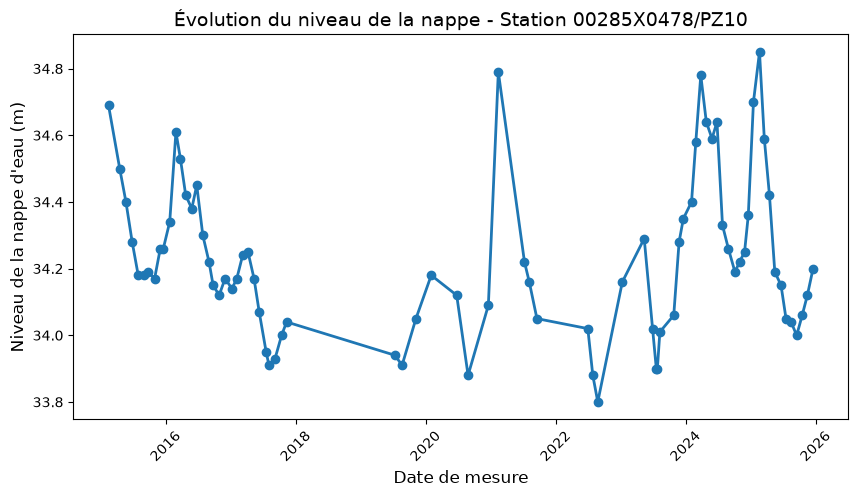

In [ ]:
# Représentation d'une série temporelle d'une station
station_cible = '00285X0478/PZ10'
df_station = chroniques[chroniques['code_bss'] == station_cible]
df_station = df_station.sort_values(by='date_mesure')

plt.figure(figsize=(10, 5))
plt.plot(
    df_station['date_mesure'], 
    df_station['niveau_nappe_eau'], 
    marker='o',         # Ajoute un point sur chaque mesure réelle
    linestyle='-',      # Relie les points par une ligne
    color='#1f77b4', 
    linewidth=2
)

plt.title(f"Évolution du niveau de la nappe - Station {station_cible}", fontsize=14)
plt.xlabel("Date de mesure", fontsize=12)
plt.ylabel("Niveau de la nappe d'eau (m)", fontsize=12)
plt.xticks(rotation=45) # Penche les dates pour éviter qu'elles ne se superposent
plt.grid(True, linestyle='--', alpha=0.7)
plt.tight_layout()

# Nettoyage et standardisation des données

Les séries temporelles de Hub'eau donnent des mesures des nappes phréatiques à des dates différentes entre les stations.  
Pour les calculs futurs, on va standardiser ça en faisant une moyenne par station et par mois

In [62]:
chroniques['date_mois_annee'] = chroniques['date_mesure'].dt.to_period('M')
chroniques

chroniques_niveau_mensuel = (chroniques.groupby(["code_bss", "date_mois_annee"])
              .agg({
                  "niveau_nappe_eau":"mean",
                  "profondeur_nappe":"mean"
              })
              .reset_index()
    )
chroniques_niveau_mensuel["date_mesure"] = chroniques_niveau_mensuel["date_mois_annee"].dt.to_timestamp()
chroniques_niveau_mensuel['date_mesure'] = pd.to_datetime(chroniques_niveau_mensuel['date_mesure'])
print("Les données ont été normalisées en moyenne par mois pour chaque station.")

Les données ont été normalisées en moyenne par mois pour chaque station.


# 1. Répartition des usines et des stations hydrologiques dans le Nord

Text(0.5, 1.0, 'Répartition des usines ICPE et des stations hydrologiques dans le département')

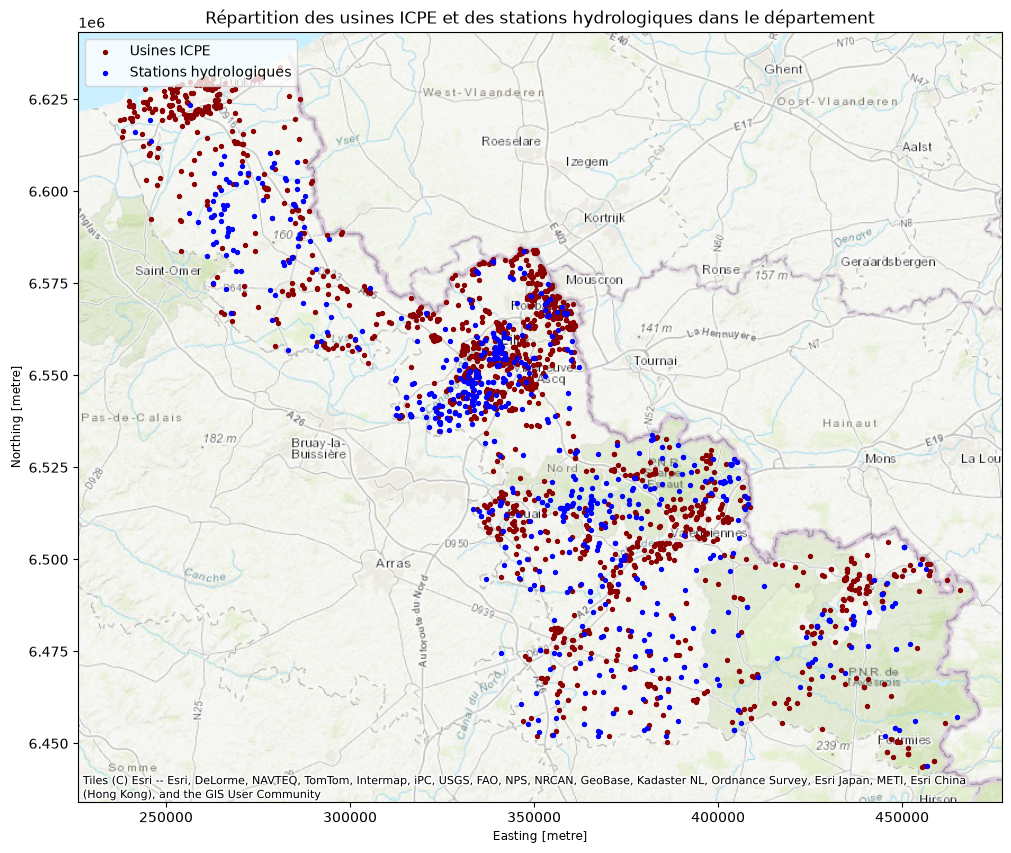

In [63]:
# Stations (points bleus, taille réduite, avec un fin contour blanc pour la lisibilité)
ax = plt.subplots(figsize=(12, 10))[1]
installations_indust.to_crs(epsg=3857).plot(ax=ax, color="darkred", markersize=8, label="Usines ICPE", zorder=1)
stations.to_crs(epsg=3857).plot(ax=ax, color="blue", markersize=8, label="Stations hydrologiques", zorder=2)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap)
plt.legend(loc="upper left")
plt.title("Répartition des usines ICPE et des stations hydrologiques dans le département")

## On cherche la quantité d'usines par station

In [64]:
#On veut le nombre d'usines qui sont dans les 5km de chaque station
r = 5 * 1000

stations_rayon = stations.copy()
stations_rayon["geometry"] = stations_rayon.geometry.buffer(r)  #On suppose que la station prend toute la place dans un rayon de 5km autour du point où elle est réellement

usines_ds_rayon = gpd.sjoin(installations_indust, stations_rayon, how="inner", predicate="within")
nb_usine_ds_rayon = usines_ds_rayon.groupby("code_bss").size().reset_index(name="nb_usines_5km")

stations = stations.merge(nb_usine_ds_rayon, on="code_bss", how="left")
stations["nb_usines_5km"] = stations["nb_usines_5km"].fillna(0).astype(int) #On remplace les valeurs nulles par 0

#On rajoute une colonne dans le tableau chroniques qui indique la pression industrielle (nb d'usines dans un rayon de 5km qui exploitent probablement la nappe)
chroniques = chroniques.merge(stations[["code_bss", "nb_usines_5km"]], on="code_bss", how="inner")


Text(0.5, 0, 'Date')

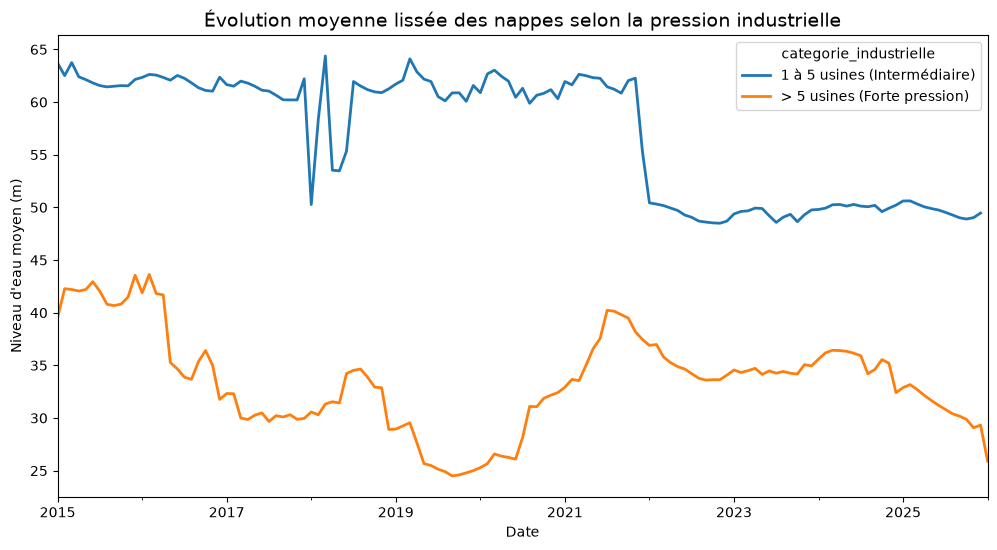

In [65]:
# Visualisation
conditions = [
    (chroniques['nb_usines_5km'] == 0),
    (chroniques['nb_usines_5km'] > 0) & (chroniques['nb_usines_5km'] <= 5),
    (chroniques['nb_usines_5km'] > 5)
]
choix = ['0 usine (Zone rurale)', '1 à 5 usines (Intermédiaire)', '> 5 usines (Forte pression)']
chroniques['categorie_industrielle'] = np.select(conditions, choix, default='Inconnu')

evolution_lisse = chroniques.groupby(['date_mois_annee', 'categorie_industrielle'])['niveau_nappe_eau'].mean().unstack()

evolution_lisse.plot(figsize=(12, 6), linewidth=2)
plt.title("Évolution moyenne lissée des nappes selon la pression industrielle", fontsize=14)
plt.ylabel("Niveau d'eau moyen (m)")
plt.xlabel("Date")

## II. Maintenant on va s'intéresser aux conditions géographiques de la nappe

## 1. Prise en compte de l'effet de l'altitude de la nappe

Les nappes phréatiques sont affectées majoritairement par 3 choses :  
- La pluie  
- L'altitude, la topographie et la géologie  
- L'industrie

1. Commençons par un état des lieux de l'altitude des différentes stations.

Text(0.5, 1.0, 'Altitude des stations hydrologiques')

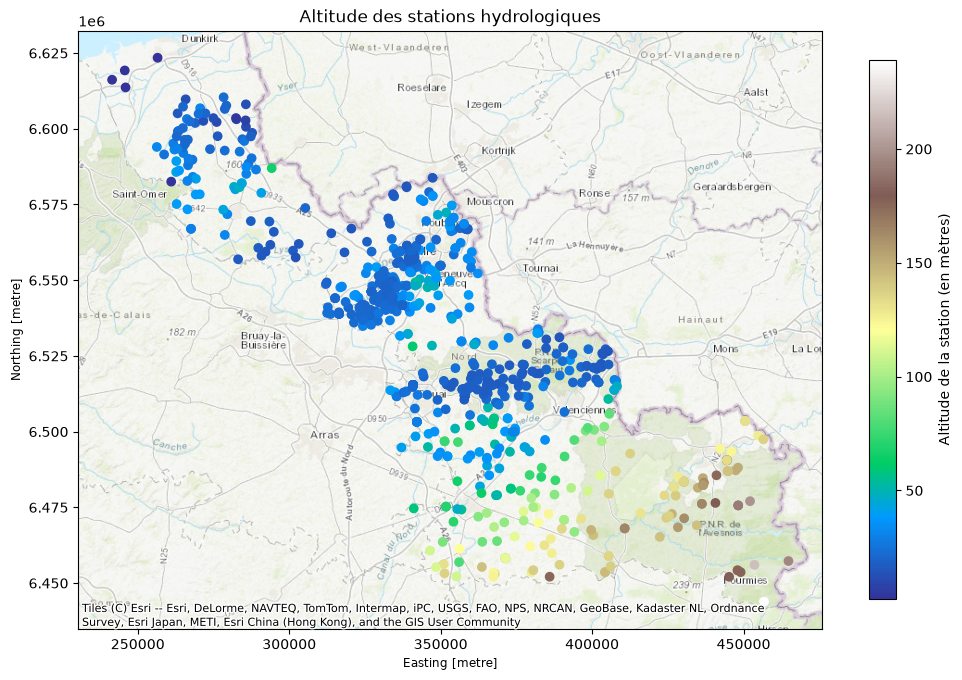

In [66]:
stations['altitude_station'] = pd.to_numeric(stations['altitude_station'])
points_carte = stations.to_crs(epsg=3857)   #on transforme le geopandas avec le code EPSG utilisé par les cartes et Google

fig, ax = plt.subplots(figsize=(12, 10))
points_carte.plot(ax=ax,
    column='altitude_station', # variable qui donne la couleur du point
    cmap='terrain', # fond de carte pour la topographie
    legend=True,                 # Affichage de la barre de gradient
    legend_kwds={
        'label': "Altitude de la station (en mètres)",
        'shrink': 0.7   #Limite la taille de la barre de la légende
    },
    zorder=2
)
ctx.add_basemap(ax, source=ctx.providers.Esri.WorldTopoMap, zorder=1)   #Fonds de carte
plt.title("Altitude des stations hydrologiques")

On veut comparer des évolutions donc on va annuler l'effet de l'altitude sur la hauteur de l'eau dans la station.  
Pour cela, on va centrer pour ne garder que les variations de niveau des nappes :  
Si on a en moyenne une hauteur de 100m pour une station, après une sécheresse qui fait baisser ce niveau à 90m, on aura -10 de variation sur notre chronique.

In [67]:
moyenne_par_station = chroniques.groupby("code_bss")["niveau_nappe_eau"].mean().reset_index()
moyenne_par_station = moyenne_par_station.rename(columns={"niveau_nappe_eau": "moyenne_de_station"})
chroniques = chroniques.merge(moyenne_par_station, on="code_bss", how="left")   #On rajoute la colonne dans le DataFrame de base en affectant à chaque ligne d'observation une colonne avec la moyenne de sa station

chroniques["niveau_eau_isole"] = chroniques["niveau_nappe_eau"] - chroniques["moyenne_de_station"]

print(chroniques[["code_bss", "date_mesure", "niveau_nappe_eau", "niveau_eau_isole"]].head(10))

KeyError: 'moyenne_de_station'

## 2. Prise en compte de l'effet de la nature des sols

On va vérifier si l'effet de la géologie doit être pris en compte.  
En effet, on peut supposer que selon la nature du sol, les nappes phréatiques peuvent se vider plus ou moins rapidement et les variations de niveau peuvent donc être impactés.  
Il y a de nombreux types de sols. On va donc se concentrer sur les 5 les plus courants pour vérifier notre hypothèse  

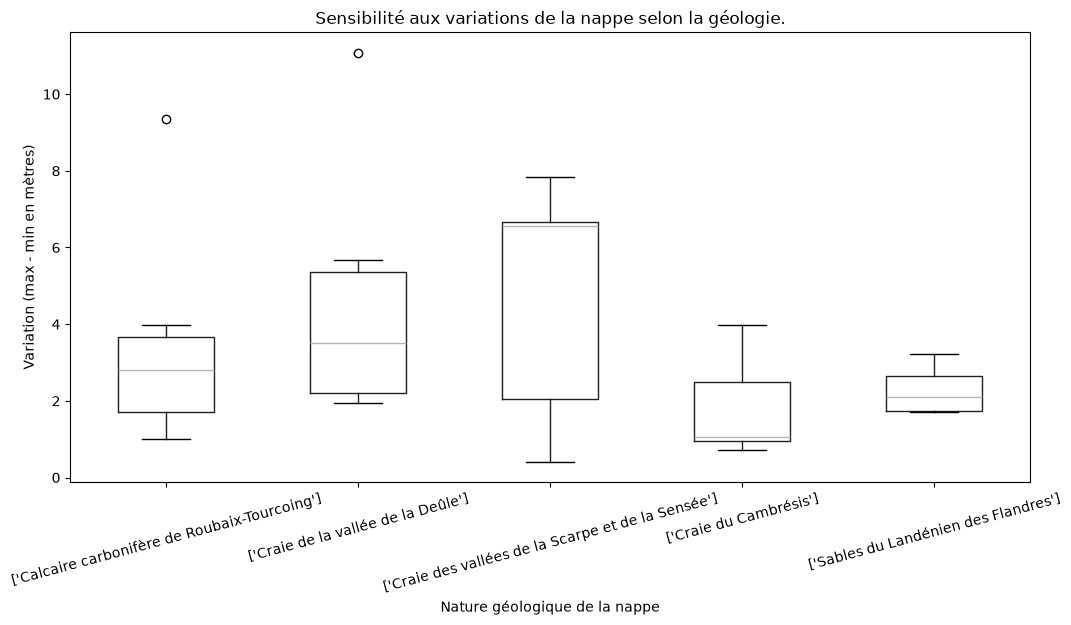

In [ ]:
#Nettoyage de type :
stations['noms_masse_eau_edl'] = stations['noms_masse_eau_edl'].astype(str)

#Calcul des variations du niveau de chaque nappe
amplitude = chroniques.groupby('code_bss')['niveau_nappe_eau'].agg(lambda x: x.max() - x.min()).reset_index()
amplitude = amplitude.rename(columns={'niveau_nappe_eau': 'amplitude_metres'})
stations = stations.merge(amplitude, on='code_bss', how='inner')

#On prend les 5 sols les plus fréquents
compte = stations.groupby('noms_masse_eau_edl').size()
tri = compte.sort_values(ascending=False)
top_5_sols = tri.head(5).index

stations_top = stations[stations['noms_masse_eau_edl'].isin(top_5_sols)]
stations_top.boxplot(column='amplitude_metres', by='noms_masse_eau_edl', grid=False, rot=15, figsize=(12, 6))
plt.title("Sensibilité aux variations de la nappe selon la géologie.")
plt.suptitle("") # sinon pPandas met un sous-titre automatique
plt.ylabel("Variation (max - min en mètres)")
plt.xlabel("Nature géologique de la nappe")
plt.show()

On va créer une colonne qui met des labels sur les types géologiques

In [ ]:
#Petit nettoyage de type
stations['noms_masse_eau_edl'] = stations['noms_masse_eau_edl'].astype(str)

#Familles de sols
conditions_geo = [
    stations['noms_masse_eau_edl'].str.contains('Craie', case=False, na=False),
    stations['noms_masse_eau_edl'].str.contains('Sable|Landénien', case=False, na=False),
    stations['noms_masse_eau_edl'].str.contains('Calcaire', case=False, na=False)
]
labels_type_station = ['Craie (Forte amplitude)', 'Sable (Faible amplitude)', 'Calcaire (Amplitude modérée)']

#On ajoute la colonne au dataframe
stations['famille_geologique'] = np.select(conditions_geo, labels_type_station, default='Autre')
print(stations['famille_geologique'].value_counts())

famille_geologique
Craie (Forte amplitude)         31
Autre                           17
Calcaire (Amplitude modérée)    11
Sable (Faible amplitude)         8
Name: count, dtype: int64


Après vérification, dans la catégorie autre, on ne retrouve quasiment que des types de sols NaN.

## 3. Prise en compte de l'effet de la topologie (distance entre la surface et la nappe)

On va vérifier si l'effet de la topologie a un effet (à annuler pour notre analyse) sur le niveau des nappes phréatiques

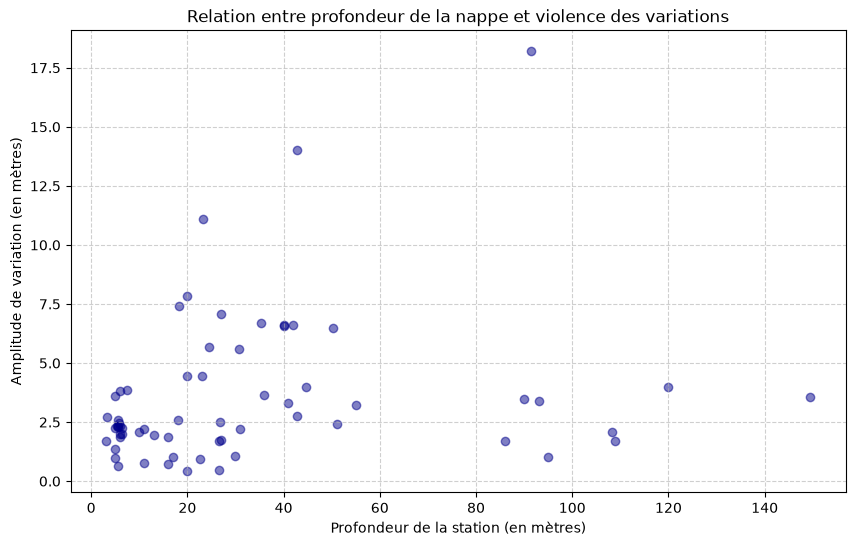

In [104]:
plt.figure(figsize=(10, 6))
# On limite l'axe X à 150m pour ne pas écraser le graphique avec les extrêmes
donnees_visuelles = stations[stations['profondeur_investigation'] < 150]

plt.scatter(donnees_visuelles['profondeur_investigation'], donnees_visuelles['amplitude_metres'], alpha=0.5, c='darkblue')
plt.title("Relation entre profondeur de la nappe et violence des variations")
plt.xlabel("Profondeur de la station (en mètres)")
plt.ylabel("Amplitude de variation (en mètres)")
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

In [105]:
#Nouvelle colonne qui donne un label topologie à la station
stations['classe_profondeur'] = 'Non renseignée'

stations.loc[stations['profondeur_investigation'] < 30, 'classe_profondeur'] = '1. Superficielle (<30m)'
stations.loc[(stations['profondeur_investigation'] >= 30) & (stations['profondeur_investigation'] <= 80), 'classe_profondeur'] = '2. Intermédiaire (30-80m)'
stations.loc[stations['profondeur_investigation'] > 80, 'classe_profondeur'] = '3. Profonde (>80m)'

print(stations['classe_profondeur'].value_counts())

classe_profondeur
1. Superficielle (<30m)      40
2. Intermédiaire (30-80m)    15
3. Profonde (>80m)           12
Name: count, dtype: int64


On voit qu'on a 40 stations superficielles qui devraient être les plus affectées par les installations industrielles.  
Le groupe des stations profondes qui ne devraient pas être très affectées par l'activité industrielle servira de groupe témoin.

## Recentrage sur les stations intéressantes
On remarque qu'on n'a plus que environ 70 stations alors qu'on en avait 730 au début.  
Cela est dû au inner join fait pour catégoriser les stations selon la géologie (avec le calcul de l'amplitude pour chaque type de sol).  
Vérifions à quoi ressemble les stations éliminées et leurs chroniques pour comprendre.

In [102]:
#On reprend la liste de toutes les stations
stations_brutes = pd.read_csv("../../data/stations_nappes.csv") 

codes_valides = chroniques['code_bss'].unique() #Stations qui ont été conservées dans le processus.
print("Stations conservées dans l'analyse : ", len(codes_valides))
print(stations[['code_bss', 'nom_commune', 'nb_mesures_piezo']].sort_values(by="nb_mesures_piezo", ascending=False).head(10))
stations_eliminees = stations_brutes[~stations_brutes['code_bss'].isin(codes_valides)]

#On regarde le nombre de mesures pour les stations éliminées :
print("Stations éliminées : ", len(stations_eliminees))
print(stations_eliminees[['code_bss', 'nom_commune', 'nb_mesures_piezo']].sort_values(by="nb_mesures_piezo", ascending=False).head(10))

Stations conservées dans l'analyse :  67
            code_bss            nom_commune  nb_mesures_piezo
30    00216X0073/PZ3               Lecelles             16982
7      00146B0007/F1                  Lille             15448
10     00143C0079/F1                Bondues             15148
14     00147D0218/P1                  Lille             13188
25     00148D0177/F2               Baisieux              9766
13     00291X0031/P1  Rombies-et-Marchipont              9176
24    00225X0077/FC2     Fresnes-sur-Escaut              8967
16     00217X0068/P1    Flines-lès-Mortagne              8580
6      00281X0004/F1                 Abscon              8573
1   00387X0184/PZCC1             Grand-Fayt              8562
Stations éliminées :  663
          code_bss          nom_commune  nb_mesures_piezo
260  00215X0140/P1           Bouvignies              9084
273  00225X0061/P1              Crespin              8236
78   00143B0102/F1            Tourcoing              6850
146  00281X0065/F1 

Donc on a un problème manifestement.  
Il esdt possible que les stations éliminées sont des stations qui n'ont pas enregistré de données entre 2015 et 2026 (car le nb_mesures_piezo est le nombre de mesures totales depuis la création de la station).

In [111]:
stations_eliminees['date_fin_mesure'] = pd.to_datetime(stations_eliminees['date_fin_mesure'])
#on regarde l'année d'arrêt de la station
stations_eliminees['annee_arret'] = stations_eliminees['date_fin_mesure'].dt.year

# On affiche l'année de fin d'activité pour les 10 plus grosses stations éliminées
colonnes_visibles = ['code_bss', 'nom_commune', 'nb_mesures_piezo', 'annee_arret']
print(stations_eliminees.sort_values(by="nb_mesures_piezo", ascending=False)[colonnes_visibles].head(10))

arret_avant_2015 = len(stations_eliminees[stations_eliminees['annee_arret'] < 2015])
jamais_mesure = len(stations_eliminees[stations_eliminees['annee_arret'].isna()])
print("Stations arrêtées définitivement avant 2015 : ", arret_avant_2015)
print("Stations sans date de fin : ", jamais_mesure)

print(stations_eliminees.loc[stations_eliminees['annee_arret'].isna()].sort_values(by="nb_mesures_piezo", ascending=False)[colonnes_visibles].head(10))

          code_bss          nom_commune  nb_mesures_piezo  annee_arret
260  00215X0140/P1           Bouvignies              9084       2004.0
273  00225X0061/P1              Crespin              8236       1996.0
78   00143B0102/F1            Tourcoing              6850       1996.0
146  00281X0065/F1              Rieulay              6676       2001.0
258  00385X0010/P1  Catillon-sur-Sambre              6617       2001.0
165  00201C0126/F1               Provin              6581       2004.0
131  00144C0005/F1            Wattrelos              6465       1987.0
413  00274X0014/F2              Anhiers              4762       2006.0
57   00273X0151/F1                Douai              4480       1997.0
307  00035X0045/P1           Loon-Plage              4260       1983.0
Stations arrêtées définitivement avant 2015 :  633
Stations sans date de fin :  30
           code_bss        nom_commune  nb_mesures_piezo  annee_arret
107   00207X0153/F1     Roost-Warendin                 0          

Donc c'est tout bon : seules les 67 stations gardées sont encore actives après 2015 et rentrent dans le cadre de notre étude.

## Création d'un indicateur qui condense toutes ces différences

## Conclusion partielle
On a annulé l'effet de l'altitude.  
On a segmenté les stations selon la géologie pour vérifier qu'elles ne biaisent pas les observations futures.  
On a segmenté les stations en un groupe expérience (stations superficielles affectées par l'industrie) et un groupe test (stations profondes).